# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [1]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 1: a graph with eight vertices

Constant ground-truth $\mu$ (Section 5.1, Figure 1): a $2 \times 4$ ladder with $|B| = 3$, $|X\setminus B| = 5$, $w_{xy} = 0.25$, $\mu_x = 1$, $T = 9$. The observed vertices are the right three vertices of the top row. Paper FRNE without absorption: $0.248499\%$.

Check of Assumption 1 (ii): every vertex has degree $\le 3$, so $\sum_y w_{xy} \le 0.75 \le 1 = \mu_x$.

This experiment adds absorption with $q(x)=0.1$ at every vertex. Since the smallest holding probability is $0.25$, the condition $q(x)\le p_{xx}$ holds. The first-passage distributions are unconditional: absorbed walks contribute no finite first-passage event.

In [2]:
# ---- parameters (edit me) ----
grid1    = GridGraph.make_grid(2, 4)                      # 2 x 4 ladder, row 0 on top
B1_coord = [(0, 1), (0, 2), (1, 2)]             # observed vertices
w1       = 0.25                                 # edge weight
mu1_kind = "constant"                           # "constant", "deg", or an array of length |X|
mu1_val  = 1.0                                  # used when mu1_kind = "constant"
T1       = 9                                    # needs T >= |X|
N1       = 10**6                                # Monte Carlo walks per pair (x, y)
seed1    = 0
q1_val   = 0.1                                  # absorption probability at every vertex

|X| = 8, |B| = 3, T = 9, t_max = 17
q(x) = 0.1; minimum p_xx = 0.25
survival probability through t_max, by starting vertex: [0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668]


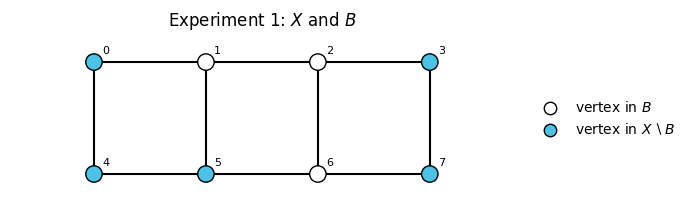

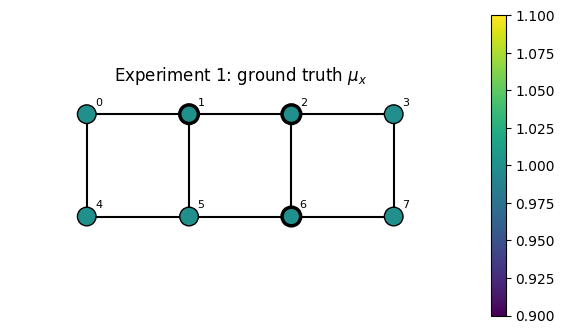

In [3]:
G1 = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
W1, mu1, B1 = G1.W, G1.mu, G1.B
P1 = G1.transition_matrix()
q1 = torch.full((len(mu1),), q1_val, dtype=torch.float64)
P1_abs = P1 - torch.diag(q1)
t_max1 = 2 * T1 - 1                             # data needed for t = 1, ..., 2T-1
print(f"|X| = {len(mu1)}, |B| = {len(B1)}, T = {T1}, t_max = {t_max1}")
print(f"q(x) = {q1_val}; minimum p_xx = {torch.diagonal(P1).min().item():.2f}")
print("survival probability through t_max, by starting vertex:",
      torch.linalg.matrix_power(P1_abs, t_max1).sum(dim=1).numpy().round(4))

plot_graph(grid1, B1, title="Experiment 1: $X$ and $B$")
plot_graph(grid1, B1, values=mu1, title=r"Experiment 1: ground truth $\mu_x$")
plt.show()

In [4]:
r1_lit = exact_first_passage_literal(P1, B1, t_max1, q=q1)
r1_emp = empirical_first_passage(P1, B1, t_max1, n_walks=N1, seed=seed1, q=q1)

summarize(P1_abs, B1, r1_emp, r1_lit)

data shape (2T-1, |B|, |B|): (17, 3, 3)
FRNE = 0.255443%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.5651 0.5021 0.3917]
 [0.5021 0.5651 0.5491]
 [0.3917 0.5491 0.5651]]
probability mass observed by t = 2T-1 (empirical):
 [[0.5655 0.5026 0.392 ]
 [0.502  0.5646 0.5486]
 [0.3909 0.5489 0.5649]]


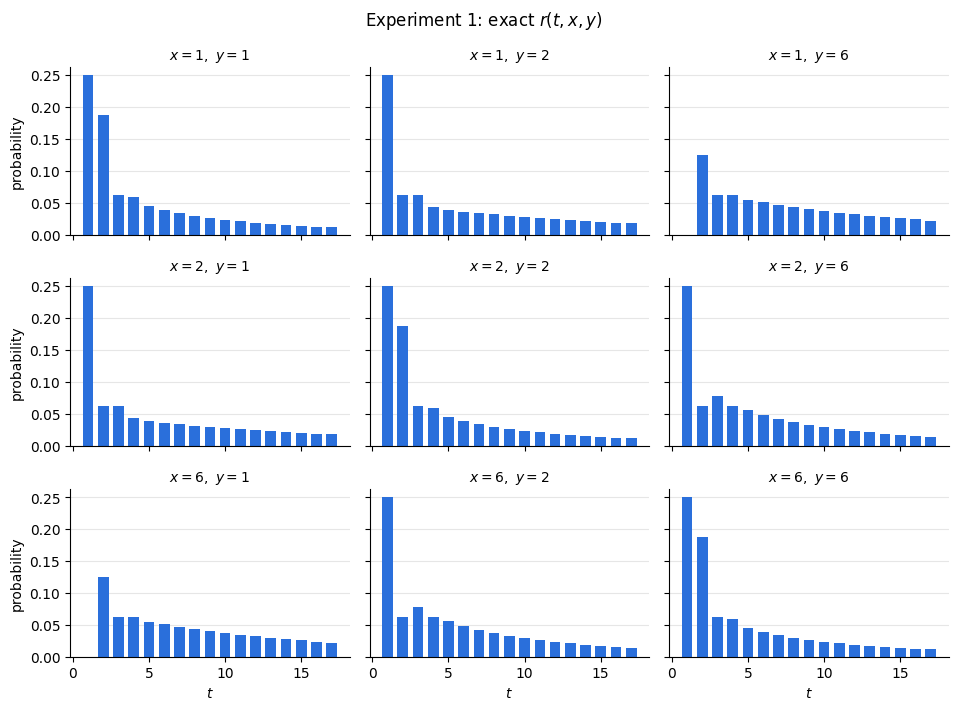

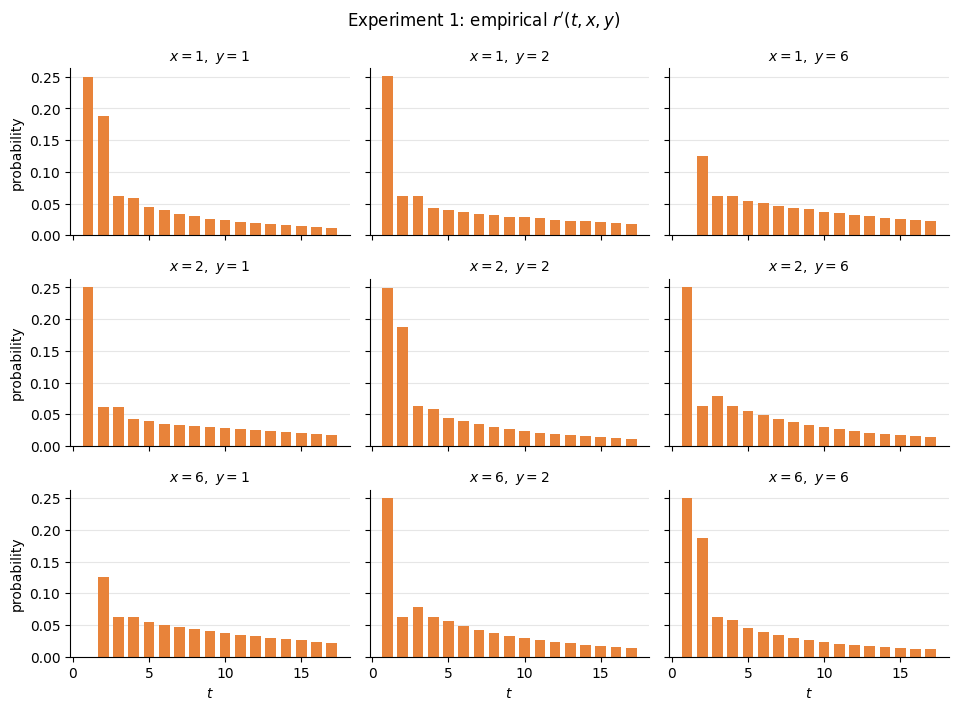

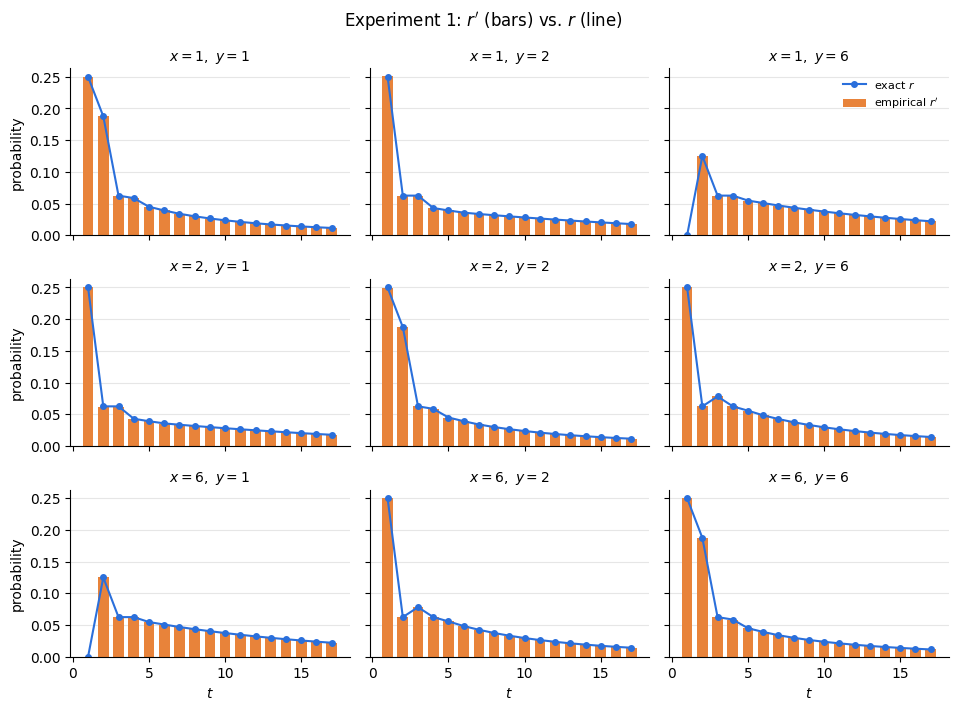

In [5]:
plot_exact_distribution(r1_lit, B1, title="Experiment 1 with absorption: exact $r(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, title="Experiment 1 with absorption: empirical $r'(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, r=r1_lit, title="Experiment 1 with absorption: $r'$ (bars) vs. $r$ (line)")
plt.show()

### Experiment 1: varying the size of $B$

Run a nested sweep from $|B|=1$ through $|B|=7$ with the same $q(x)=0.1$ absorption. For each set, compare the exact and Monte Carlo first-passage distributions using FRNE, and plot FRNE against $|B|$. The sweep uses `N1_sweep` Monte Carlo walks per ordered pair.

|B| = 1: FRNE = 0.118389%
|B| = 2: FRNE = 0.135080%
|B| = 3: FRNE = 0.225375%
|B| = 4: FRNE = 0.249766%
|B| = 5: FRNE = 0.268584%
|B| = 6: FRNE = 0.260749%
|B| = 7: FRNE = 0.273991%


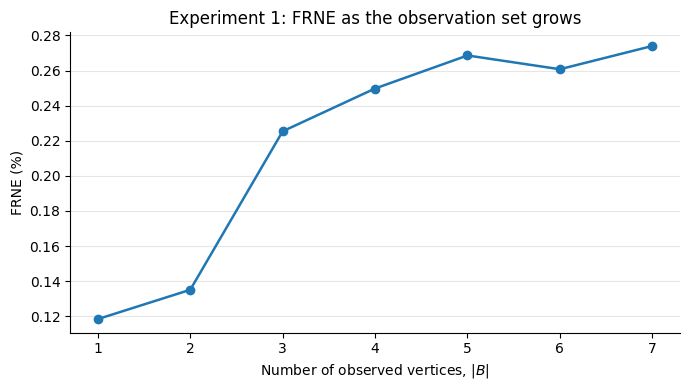

In [5]:
B1_coord = [(0, 0)]  
N1_sweep = 10**6
B1_sweep_order = B1_coord + [coord for coord in grid1 if coord not in B1_coord]
B1_sweep_sizes = list(range(1, len(grid1)))
B1_sweep_frne = []

for nB in B1_sweep_sizes:
    B_coords = B1_sweep_order[:nB]
    B_sweep = torch.tensor([G1.index[tuple(coord)] for coord in B_coords], dtype=torch.long)
    r_exact = exact_first_passage_literal(P1, B_sweep, t_max1, q=q1)
    r_empirical = empirical_first_passage(
        P1, B_sweep, t_max1, n_walks=N1_sweep, batch=min(10**4, N1_sweep),
        seed=seed1 + nB, q=q1
    )
    B1_sweep_frne.append(frne(r_exact, r_empirical))
    print(f"|B| = {nB}: FRNE = {B1_sweep_frne[-1]:.6f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(B1_sweep_sizes, B1_sweep_frne, "o-", lw=1.8)
ax.set(xticks=B1_sweep_sizes, xlabel=r"Number of observed vertices, $|B|$",
       ylabel="FRNE (%)", title="Experiment 1: FRNE as the observation set grows")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Experiment 2: the graph with nine vertices

Varying ground-truth $\mu$ (Section 5.2, Figure 4): a $3 \times 3$ grid with $|B| = 3$ (the top row), $|X\setminus B| = 6$, $w_{xy} = 1$, $\mu_x = \deg(x)$, $T = 9$. Paper FRNE: $0.188348\%$.

Here $\mu_x = \deg(x) = \sum_y w_{xy}$, so Assumption 1 (ii) holds with equality and $p_{xx} = 0$: the walk never stays put. This is the simple random walk (normalized Laplacian).

In [10]:
grid2    = GridGraph.make_grid(3, 3)
B2_coord = [(0, 0), (1, 2), (2, 1)]
w2       = 1.0
mu2_kind = "deg"
mu2_val  = 1.0
T2       = 9
N2       = 10**6
seed2    = 0

|X| = 9, |B| = 3, T = 9, t_max = 17


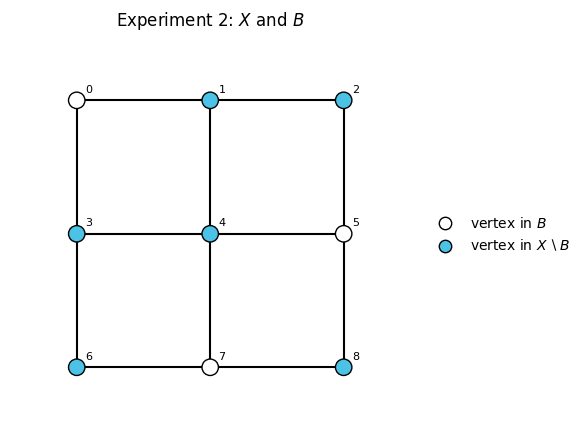

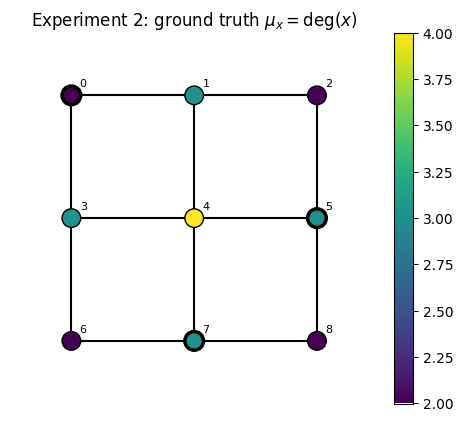

In [11]:
G2 = GridGraph(grid2, B2_coord, w=w2, mu=mu2_kind, mu_val=mu2_val)
W2, mu2, B2 = G2.W, G2.mu, G2.B
P2 = G2.transition_matrix()
t_max2 = 2 * T2 - 1
print(f"|X| = {len(mu2)}, |B| = {len(B2)}, T = {T2}, t_max = {t_max2}")

plot_graph(grid2, B2, title="Experiment 2: $X$ and $B$")
plot_graph(grid2, B2, values=mu2, title=r"Experiment 2: ground truth $\mu_x = \deg(x)$")
plt.show()

In [12]:
r2 = exact_first_passage_literal(P2, B2, t_max2)
r2_emp = empirical_first_passage(P2, B2, t_max2, n_walks=N2, seed=seed2)

summarize(P2, B2, r2_emp, r2, paper_frne=0.188348)

data shape (2T-1, |B|, |B|): (17, 3, 3)
FRNE = 0.227907%   (paper: 0.188348%)
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.7566 0.8015 0.8015]
 [0.6563 0.8694 0.8241]
 [0.6563 0.8241 0.8694]]
probability mass observed by t = 2T-1 (empirical):
 [[0.7563 0.8013 0.8013]
 [0.6565 0.8698 0.824 ]
 [0.6552 0.824  0.8685]]


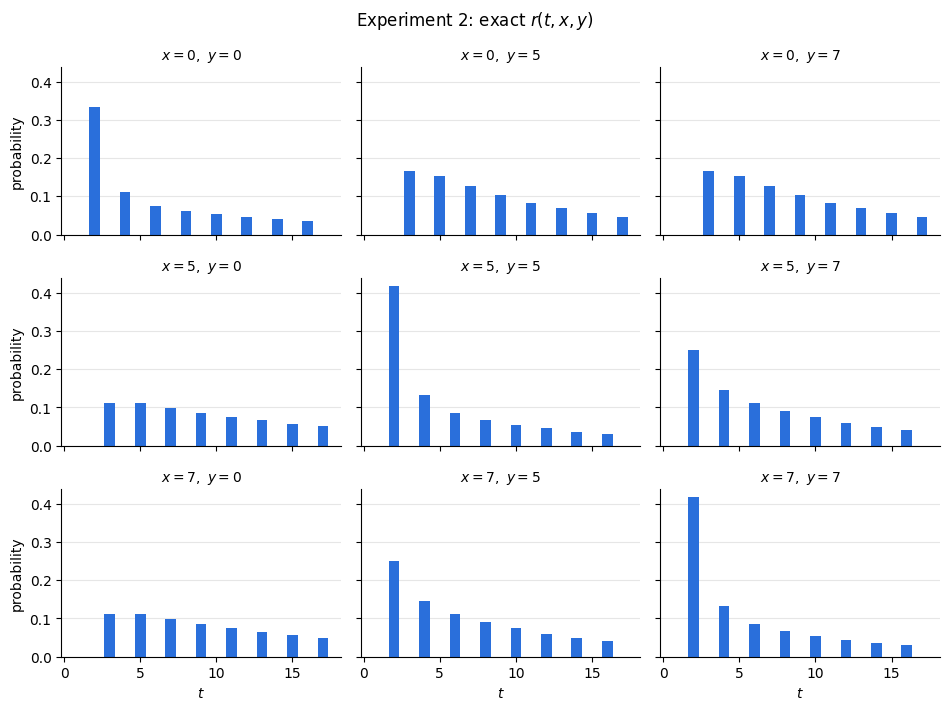

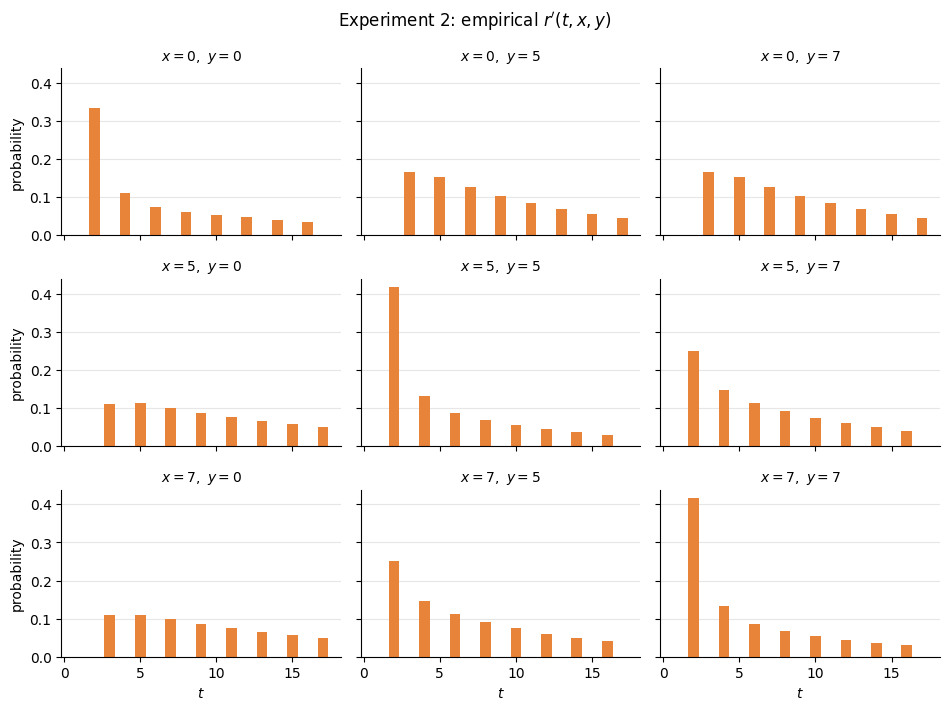

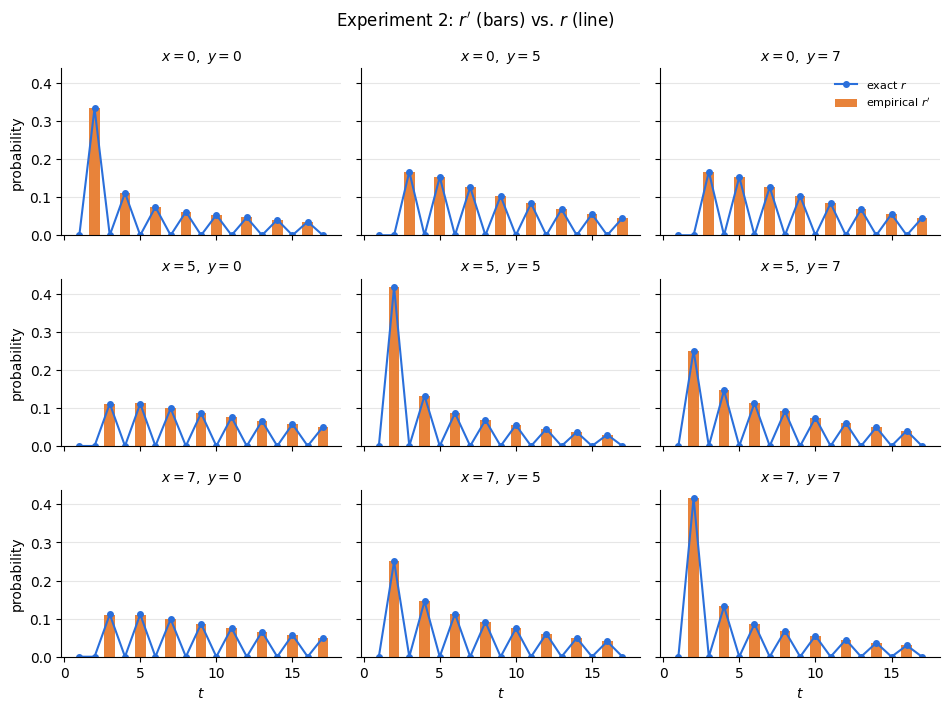

In [13]:
plot_exact_distribution(r2, B2, title="Experiment 2: exact $r(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, title="Experiment 2: empirical $r'(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, r=r2, title="Experiment 2: $r'$ (bars) vs. $r$ (line)")
plt.show()

|B| = 1: FRNE = 0.379751%
|B| = 2: FRNE = 0.125163%
|B| = 3: FRNE = 0.190556%
|B| = 4: FRNE = 0.189648%
|B| = 5: FRNE = 0.209747%
|B| = 6: FRNE = 0.194370%
|B| = 7: FRNE = 0.204700%


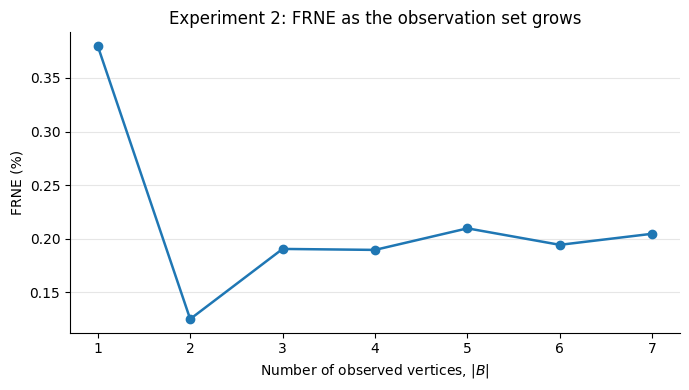

In [14]:
B2_coord = [(0, 0)]  
N2_sweep = 10**6
B2_sweep_order = B2_coord + [coord for coord in grid2 if coord not in B2_coord]
B2_sweep_sizes = list(range(1, len(grid1)))
B2_sweep_frne = []

for nB in B2_sweep_sizes:
    B_coords = B2_sweep_order[:nB]
    B_sweep = torch.tensor([G2.index[tuple(coord)] for coord in B_coords], dtype=torch.long)
    r_exact = exact_first_passage_literal(P2, B_sweep, t_max1)
    r_empirical = empirical_first_passage(
        P2, B_sweep, t_max1, n_walks=N2_sweep, batch=min(10**4, N2_sweep), seed=seed2 + nB
    )
    B2_sweep_frne.append(frne(r_exact, r_empirical))
    print(f"|B| = {nB}: FRNE = {B2_sweep_frne[-1]:.6f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(B2_sweep_sizes, B2_sweep_frne, "o-", lw=1.8)
ax.set(xticks=B2_sweep_sizes, xlabel=r"Number of observed vertices, $|B|$",
       ylabel="FRNE (%)", title="Experiment 2: FRNE as the observation set grows")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Experiment 3: an irregular shape with variable weights (not in the paper)

A 14-vertex shape on a $4 \times 5$ lattice (`X` = vertex, `o` = empty):

```
X o o o X
X X X X X
X X X X X
o X o X o
```

It has 17 edges. Two "horns" hang off the top corners and two "legs" hang off the bottom. Unlike the paper's experiments, the **edge weights vary**: each $w_{xy}$ is drawn from $\mathrm{Uniform}(0.2, 1)$ with a fixed seed. The centrality is $\mu_x = \deg(x)$. We observe the four tips, $B = \{(0,0), (0,4), (3,1), (3,3)\}$, so $|B| = 4$ and $|X \setminus B| = 10$, and we take $T = |X| = 14$.

Check of Assumption 1 (ii): every $w_{xy} \le 1$, so $\sum_y w_{xy} \le \deg(x) = \mu_x$. Since the weights are $< 1$, $p_{xx} > 0$ at every vertex: the walk is lazy, and lazier where the edges are weak.

To try other weights, set `w3` to a number, a dict `{((r1, c1), (r2, c2)): w}`, a function `w(p, q)` of the two coordinates, or an $n \times n$ matrix.

In [ ]:
pattern3 = ["X o o o X",
            "X X X X X",
            "X X X X X",
            "o X o X o"]
grid3    = GridGraph.grid_from_pattern(pattern3)
B3_coord = [(0, 0), (0, 4), (3, 1), (3, 3)]
w3       = "random"
w3_low, w3_high, w3_seed = 0.2, 1.0, 0
mu3_kind = "deg"
T3       = len(grid3)
N3       = 10**6
seed3    = 0

In [ ]:
G3 = GridGraph(grid3, B3_coord, w=w3, mu=mu3_kind,
               w_low=w3_low, w_high=w3_high, w_seed=w3_seed)
W3, mu3, B3 = G3.W, G3.mu, G3.B
P3 = G3.transition_matrix()
t_max3 = 2 * T3 - 1
print(f"|X| = {len(mu3)}, |E| = {len(G3.edges)}, |B| = {len(B3)}, T = {T3}, t_max = {t_max3}")
print("p_xx (staying probabilities):", torch.diagonal(P3).numpy().round(3))

plot_graph(G3.grid, B3, title="Experiment 3: $X$ and $B$")
plot_graph(G3.grid, B3, values=mu3, W=W3, title=r"Experiment 3: ground truth $\mu_x = \deg(x)$ and $w_{xy}$")
plt.show()

In [ ]:
r3 = exact_first_passage_literal(P3, B3, t_max3)
r3_emp = empirical_first_passage(P3, B3, t_max3, n_walks=N3, seed=seed3)

summarize(P3, B3, r3_emp, r3)

In [ ]:
plot_exact_distribution(r3, B3, title="Experiment 3: exact $r(t, x, y)$")
plot_empirical_distribution(r3_emp, B3, r=r3, title="Experiment 3: $r'$ (bars) vs. $r$ (line)")
plt.show()